# Diniz Ch.3 — Linearly constrained complex LMS array

Example 3.9：4 sensors、0.15 m spacing、20/70 MHz signals、2 GHz sampling。修正 complex power gradient 為 conj(y)x。

## 1. Setup

In [1]:
from pathlib import Path
import sys
from functools import partial

import numpy as np

project_root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "adsp").is_dir())
if str(project_root) not in sys.path:
  sys.path.insert(0, str(project_root))

from adsp import data, training, statistics as stats
from adsp import plotting as plot
from adsp import filters as af
from adsp import equalization as ae
from adsp.datasets import SampleBatch

plot.use_dark()

## 2. Array geometry and reproducible snapshots

In [2]:
from adsp import beamforming as bf

n_samples, seed, n_sensors = 130_000, 42, 4
c, sample_rate, spacing = 3e8, 2e9, 0.15
target_frequency, interference_frequency = 20e6, 70e6
target = bf.steering(n_sensors, 90.0, spacing_wavelengths=spacing * target_frequency / c, angle_convention="axis")
interferer = bf.steering(n_sensors, 30.0, spacing_wavelengths=spacing * interference_frequency / c,
                         angle_convention="axis")
batch = bf.snapshots(n_samples, rng=np.random.default_rng(seed), target_vector=target, interference_vector=interferer,
                     target_power=1.0, interference_power=1.0, noise_var=0.01,
                     target_frequency=target_frequency / sample_rate,
                     interference_frequency=interference_frequency / sample_rate)

## 3. Constraint and common training interface

In [3]:
model = bf.ConstrainedLMS(constraint=target, desired_gain=np.array([1.0]), mu=0.01)
result = training.run(model, batch, name="Constrained LMS")
gain = np.vdot(result.w_final, target)
assert np.allclose(gain, 1.0)
rejection = stats.power_db(abs(gain)**2 / abs(np.vdot(result.w_final, interferer))**2)
print("Constraint gain:", gain, "interference rejection:", rejection, "dB")

Constraint gain: (1+2.160718837006312e-16j) interference rejection: 27.60244220276548 dB


## 4. Output power, waveforms and frequency-specific array patterns

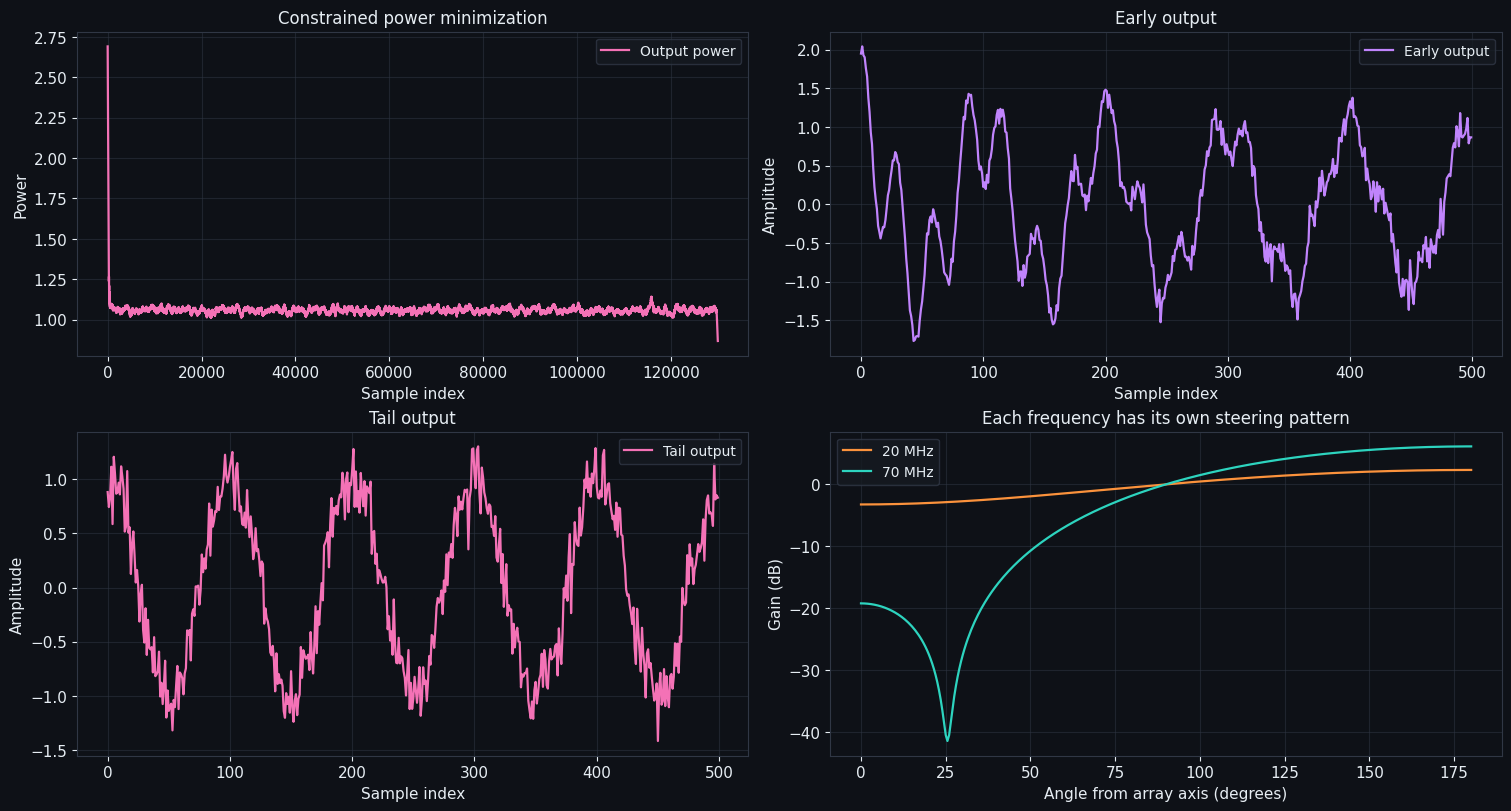

In [4]:
fig, grid = plot.axes(rows=2, cols=2)
plot.lines({"Output power": result.extras["output_power"]}, ax=grid[0, 0], window=501,
           title="Constrained power minimization", ylabel="Power")
plot.lines({"Early output": result.y[:500].real}, ax=grid[0, 1], title="Early output")
plot.lines({"Tail output": result.y[-500:].real}, ax=grid[1, 0], title="Tail output")
angles = np.linspace(0, 180, 361)
patterns = {}
for label, frequency in (("20 MHz", target_frequency), ("70 MHz", interference_frequency)):
  response = bf.response(result.w_final, np.cos(np.deg2rad(angles)), spacing_wavelengths=spacing * frequency / c)
  patterns[label] = (angles, np.abs(response)**2)
plot.lines(patterns, ax=grid[1, 1], scale="db", xlabel="Angle from array axis (degrees)", ylabel="Gain (dB)",
           title="Each frequency has its own steering pattern")
plot.show(fig)

## 原始題目附圖

以下保留上傳 notebook 的說明圖。

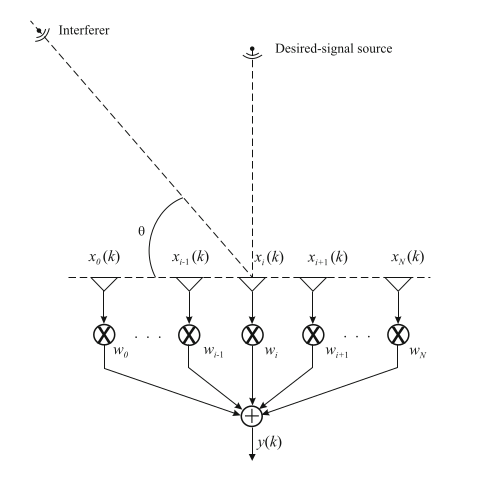